# What makes hotel bookings more expensive and more likely to be cancelled?

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
import missingno as msno

from scipy.stats import ttest_ind
from scipy.stats import t

from statsmodels.stats.proportion import proportions_ztest, proportion_confint

pd.set_option('display.max_columns', None)

## Data Preparation:

Dataset Loading

In [2]:
path = 'hotel_bookings.csv'
df = pd.read_csv(path)

In [3]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Instances × attributes:", df.shape[0] * df.shape[1])

Number of rows: 119390
Number of columns: 32
Instances × attributes: 3820480


In [5]:
col_summary = pd.DataFrame({
    "Column:": df.columns, "Data type:": df.dtypes.values, 
    "Unique Values": [df[col].nunique() for col in df.columns],
    "Sample Values": [df[col].dropna().unique()[:10].tolist() for col in df.columns]
    })

col_summary


,Column:,Data type:,Unique Values,Sample Values
0,hotel,str,2,"[Resort Hotel, City Hotel]"
1,is_canceled,int64,2,"[0, 1]"
2,lead_time,int64,479,"[342, 737, 7, 13, 14, 0, 9, 85, 75, 23]"
3,arrival_date_year,int64,3,"[2015, 2016, 2017]"
4,arrival_date_month,str,12,"[July, August, September, October, November, D..."
5,arrival_date_week_number,int64,53,"[27, 28, 29, 30, 31, 32, 33, 34, 35, 36]"
6,arrival_date_day_of_month,int64,31,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]"
7,stays_in_weekend_nights,int64,17,"[0, 1, 2, 4, 3, 6, 13, 8, 5, 7]"
8,stays_in_week_nights,int64,35,"[0, 1, 2, 3, 4, 5, 10, 11, 8, 6]"
9,adults,int64,14,"[2, 1, 3, 4, 40, 26, 50, 27, 55, 0]"


#### Handling Missing Values:

In [6]:
df.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [7]:
df.isnull().sum().sum()

np.int64(129425)

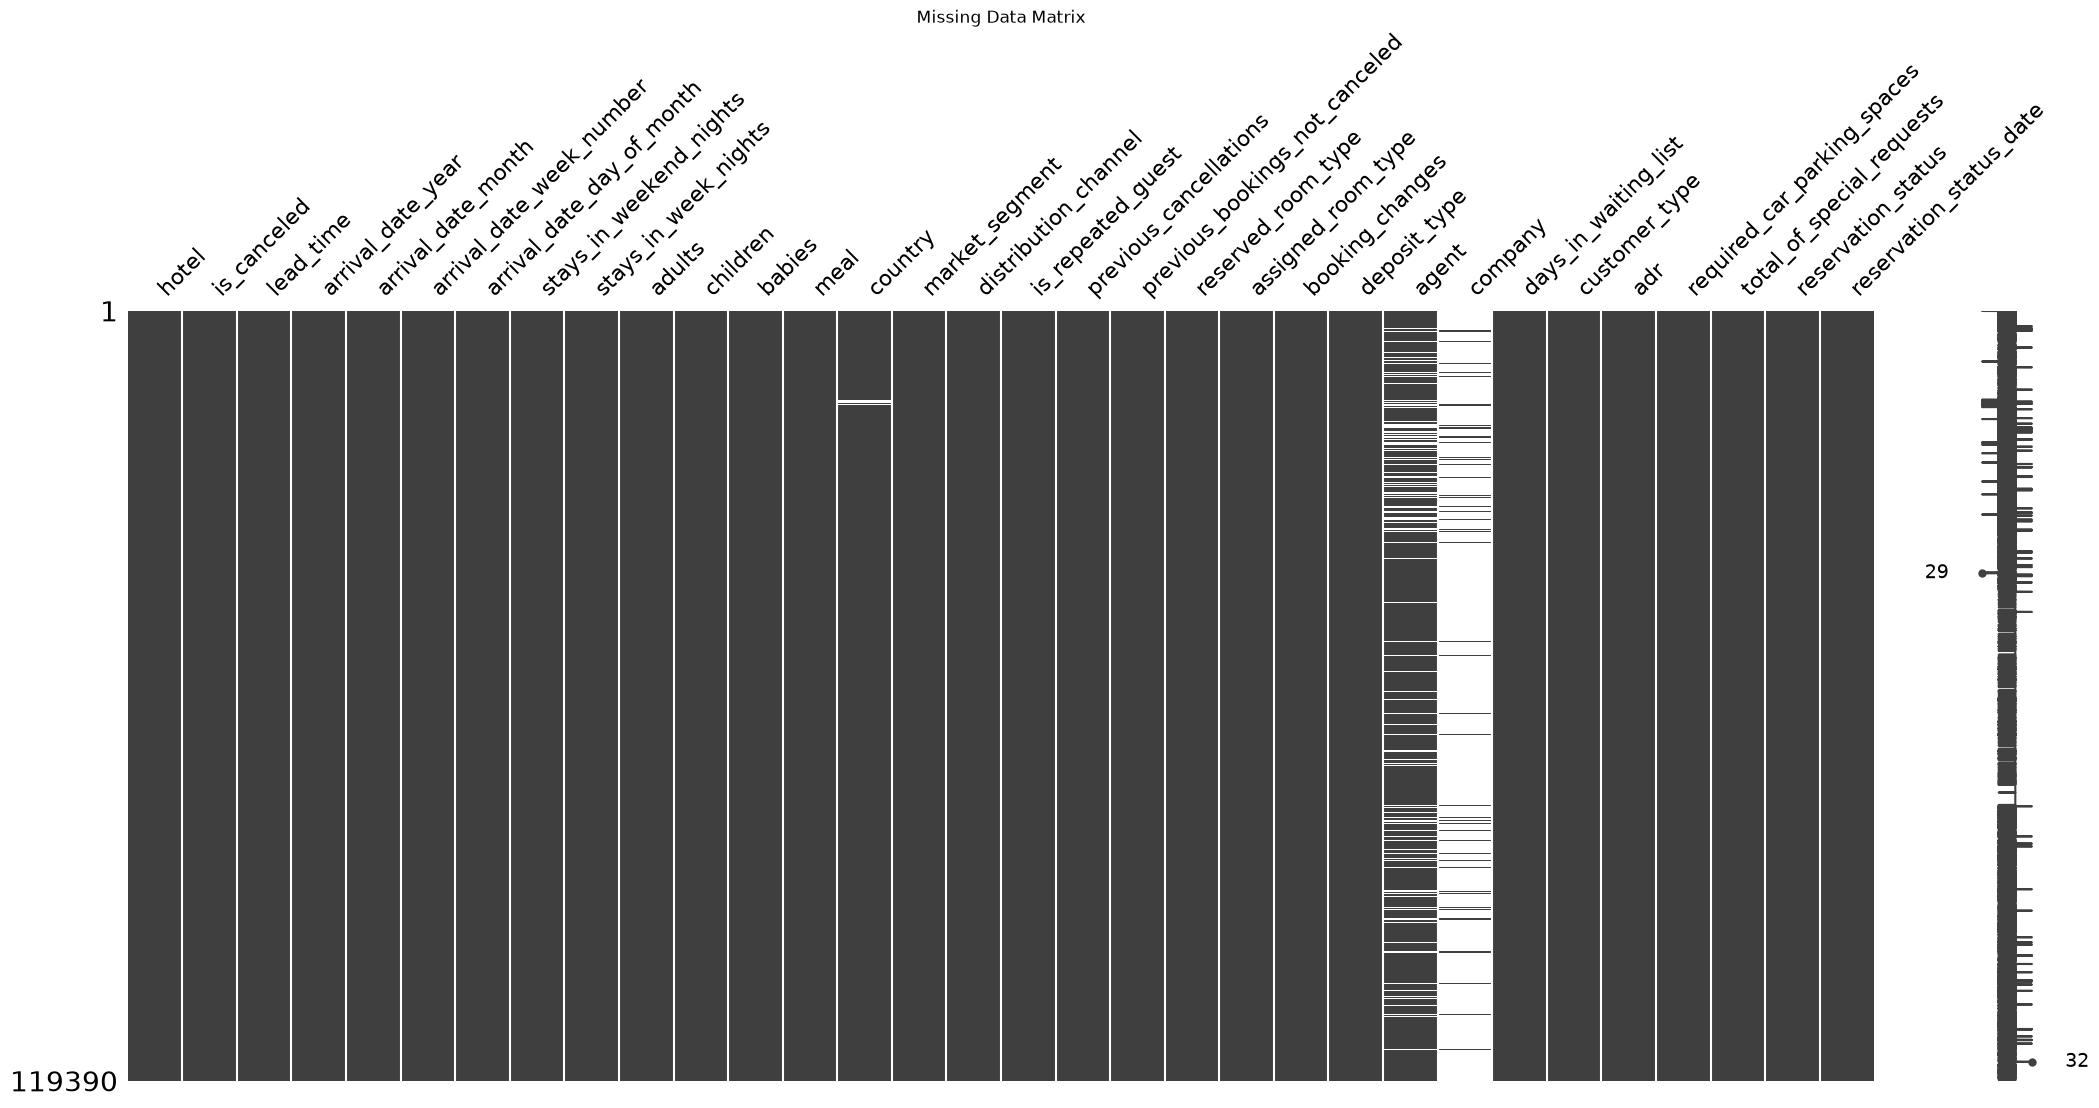

In [8]:
msno.matrix(df)
plt.title("Missing Data Matrix")
plt.show()

In [9]:
df["children"] = df["children"].fillna(0)
df["country"] = df["country"].fillna("N/A")
df["agent"] = df["agent"].fillna("NoAgent").astype(str)
df["company"] = df["company"].fillna("NoCompany").astype(str)

print(df[["children", "country", "agent", "company"]].isnull().sum())


children    0
country     0
agent       0
company     0
dtype: int64


In [10]:
df['agent'] = df['agent'].astype(str)
df['company'] = df['company'].astype(str)
df["reservation_status_date"] = pd.to_datetime(df["reservation_status_date"],errors="coerce")

In [11]:
df['total_stay'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['total_guests'] = df['adults'] + df['children'] + df['babies']
df['is_family'] = ((df['children'] + df['babies']) > 0).astype(int)
df['includes_weekends'] = (df['stays_in_weekend_nights'] > 0).astype(int)


date_str = df['arrival_date_day_of_month'].astype(str) + "-" +  df["arrival_date_month"].astype(str) + "-" + df["arrival_date_year"].astype(str)
df['arrival_date'] = pd.to_datetime(date_str, format='%d-%B-%Y', errors='coerce')

print(df[["arrival_date", "total_stay", "total_guests", "is_family", "includes_weekends"]].head(10))
print("\nInvalid arrival dates:", df["arrival_date"].isna().sum())

  arrival_date  total_stay  total_guests  is_family  includes_weekends
0   2015-07-01           0           2.0          0                  0
1   2015-07-01           0           2.0          0                  0
2   2015-07-01           1           1.0          0                  0
3   2015-07-01           1           1.0          0                  0
4   2015-07-01           2           2.0          0                  0
5   2015-07-01           2           2.0          0                  0
6   2015-07-01           2           2.0          0                  0
7   2015-07-01           2           2.0          0                  0
8   2015-07-01           3           2.0          0                  0
9   2015-07-01           3           2.0          0                  0

Invalid arrival dates: 0


In [12]:
print("Family indicator:")
display(df["is_family"].value_counts(dropna=False))

print("\nWeekend indicator:")
display(df["includes_weekends"].value_counts(dropna=False))

print("\nTotal stay duration:")
display(df["total_stay"].describe())

print("\nTotal guests:")
display(df["total_guests"].describe())

print("\nMissing values in engineered features:")
display(df[["arrival_date", "total_stay", "total_guests", "is_family", "includes_weekends"]].isnull().sum())

Family indicator:


is_family
0    110058
1      9332
Name: count, dtype: int64


Weekend indicator:


includes_weekends
1    67392
0    51998
Name: count, dtype: int64


Total stay duration:


count    119390.000000
mean          3.427900
std           2.557439
min           0.000000
25%           2.000000
50%           3.000000
75%           4.000000
max          69.000000
Name: total_stay, dtype: float64


Total guests:


count    119390.000000
mean          1.968239
std           0.722394
min           0.000000
25%           2.000000
50%           2.000000
75%           2.000000
max          55.000000
Name: total_guests, dtype: float64


Missing values in engineered features:


arrival_date         0
total_stay           0
total_guests         0
is_family            0
includes_weekends    0
dtype: int64

In [13]:
print("\nRemaining missing values:")
missing = df.isnull().sum()
print(missing[missing > 0].sort_values(ascending=False))


Remaining missing values:
Series([], dtype: int64)


#### Checking for Invalid Rows:

In [14]:
checks = {
    "Negative adults": df["adults"] < 0,
    "Negative children": df["children"] < 0,
    "Negative babies": df["babies"] < 0,
    "Zero total guests": df["total_guests"] == 0,
    "Negative weekend nights": df["stays_in_weekend_nights"] < 0,
    "Negative weekday nights": df["stays_in_week_nights"] < 0,
    "Negative or zero total stay": df["total_stay"] <= 0,
    "Negative lead time": df["lead_time"] < 0,
    "Negative ADR or zero": df["adr"] <= 0,
    "Negative booking changes": df["booking_changes"] < 0,
    "Negative previous cancellations": df["previous_cancellations"] < 0,
    "Negative previous bookings not canceled": df["previous_bookings_not_canceled"] < 0
}

print("Invalid-value checks:")
for name, condition in checks.items():
    print(f"{name}: {condition.sum()}")

invalid_mask = pd.DataFrame(checks, index=df.index).any(axis=1)

print("\nTotal rows with at least one invalid condition:", invalid_mask.sum())

Invalid-value checks:
Negative adults: 0
Negative children: 0
Negative babies: 0
Zero total guests: 180
Negative weekend nights: 0
Negative weekday nights: 0
Negative or zero total stay: 715
Negative lead time: 0
Negative ADR or zero: 1960
Negative booking changes: 0
Negative previous cancellations: 0
Negative previous bookings not canceled: 0

Total rows with at least one invalid condition: 1991


In [15]:
rows_before = len(df)
invalid_rows = invalid_mask.sum()

df = df.loc[~invalid_mask].copy()

print("Rows before cleaning:", rows_before)
print("Invalid rows removed:", invalid_rows)
print("Rows after cleaning:", len(df))
print("Updated dataset shape:", df.shape)

Rows before cleaning: 119390
Invalid rows removed: 1991
Rows after cleaning: 117399
Updated dataset shape: (117399, 37)


#### Checking for Outliers:

In [16]:
cap_cols = ["total_guests",  "total_stay", "adr", "lead_time", "stays_in_weekend_nights", "stays_in_week_nights"]

outlier_results = []

for col in cap_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_fence = Q1 - 1.5 * IQR
    upper_fence = Q3 + 1.5 * IQR

    lower_count = (df[col] < lower_fence).sum()
    upper_count = (df[col] > upper_fence).sum()

    outlier_results.append({ "Column": col, 
                        "Lower Fence": round(lower_fence, 2), 
                        "Upper Fence": round(upper_fence, 2), 
                        "Lower Outliers": lower_count, 
                        "Upper Outliers": upper_count, 
                        "Total Outliers": lower_count + upper_count, 
                        "Outlier %": round((lower_count + upper_count) / len(df) * 100, 2)
                    })

outlier_summary = pd.DataFrame(outlier_results)
display(outlier_summary)

,Column,Lower Fence,Upper Fence,Lower Outliers,Upper Outliers,Total Outliers,Outlier %
0,total_guests,2.00,2.0,21725,14435,36160,30.80
1,total_stay,-1.00,7.0,0,5195,5195,4.43
2,adr,-12.67,209.2,0,4050,4050,3.45
3,lead_time,-195.50,376.5,0,2960,2960,2.52
4,stays_in_weekend_nights,-3.00,5.0,0,254,254,0.22
5,stays_in_week_nights,-2.00,6.0,0,3312,3312,2.82


#### Removing Redundant Columns:

In [17]:
print("Dataset shape:", df.shape)

print("\nColumn names and data types:")
print(df.dtypes.to_string())

print("\nRemaining missing values:", df.isnull().sum().sum())

Dataset shape: (117399, 37)

Column names and data types:
hotel                                        str
is_canceled                                int64
lead_time                                  int64
arrival_date_year                          int64
arrival_date_month                           str
arrival_date_week_number                   int64
arrival_date_day_of_month                  int64
stays_in_weekend_nights                    int64
stays_in_week_nights                       int64
adults                                     int64
children                                 float64
babies                                     int64
meal                                         str
country                                      str
market_segment                               str
distribution_channel                         str
is_repeated_guest                          int64
previous_cancellations                     int64
previous_bookings_not_canceled             int64
reserved_ro

In [18]:
redundant_cols = ["arrival_date_year", "arrival_date_month", "arrival_date_week_number", "arrival_date_day_of_month", "reservation_status"]

df = df.drop(columns=redundant_cols)

print("Updated dataset shape:", df.shape)

Updated dataset shape: (117399, 32)


#### Handling Categorical Columns:

In [19]:
print("Object/category columns:")
print(df.select_dtypes(include=["object", "category"]).nunique().sort_values())

print("\nBinary columns:")
for col in df.columns:
    if df[col].nunique() == 2:
        print(col, ":", df[col].unique())

Object/category columns:
hotel                     2
deposit_type              3
customer_type             4
distribution_channel      5
meal                      5
market_segment            8
reserved_room_type        9
assigned_room_type       11
country                 178
agent                   333
company                 344
dtype: int64

Binary columns:
hotel : <StringArray>
['Resort Hotel', 'City Hotel']
Length: 2, dtype: str
is_canceled : [0 1]
is_repeated_guest : [0 1]
is_family : [0 1]
includes_weekends : [0 1]


C:\Users\Avnish\AppData\Local\Temp\ipykernel_33872\1884780601.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.select_dtypes(include=["object", "category"]).nunique().sort_values())


In [20]:
categorical_cols = [
    "hotel",
    "meal",
    "deposit_type",
    "customer_type",
    "distribution_channel",
    "market_segment",
    "reserved_room_type",
    "assigned_room_type"
]

df = pd.get_dummies(df, columns=categorical_cols, dtype=int)

print("Updated dataset shape:", df.shape)
display(df.head())

Updated dataset shape: (117399, 71)


,is_canceled,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,country,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,reservation_status_date,total_stay,total_guests,is_family,includes_weekends,arrival_date,hotel_City Hotel,hotel_Resort Hotel,meal_BB,meal_FB,meal_HB,meal_SC,meal_Undefined,deposit_type_No Deposit,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Contract,customer_type_Group,customer_type_Transient,customer_type_Transient-Party,distribution_channel_Corporate,distribution_channel_Direct,distribution_channel_GDS,distribution_channel_TA/TO,distribution_channel_Undefined,market_segment_Aviation,market_segment_Complementary,market_segment_Corporate,market_segment_Direct,market_segment_Groups,market_segment_Offline TA/TO,market_segment_Online TA,market_segment_Undefined,reserved_room_type_A,reserved_room_type_B,reserved_room_type_C,reserved_room_type_D,reserved_room_type_E,reserved_room_type_F,reserved_room_type_G,reserved_room_type_H,reserved_room_type_L,assigned_room_type_A,assigned_room_type_B,assigned_room_type_C,assigned_room_type_D,assigned_room_type_E,assigned_room_type_F,assigned_room_type_G,assigned_room_type_H,assigned_room_type_I,assigned_room_type_K,assigned_room_type_L
2,0,7,0,1,1,0.0,0,GBR,0,0,0,0,NoAgent,NoCompany,0,75.0,0,0,2015-07-02,1,1.0,0,0,2015-07-01,0,1,1,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
3,0,13,0,1,1,0.0,0,GBR,0,0,0,0,304.0,NoCompany,0,75.0,0,0,2015-07-02,1,1.0,0,0,2015-07-01,0,1,1,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
4,0,14,0,2,2,0.0,0,GBR,0,0,0,0,240.0,NoCompany,0,98.0,0,1,2015-07-03,2,2.0,0,0,2015-07-01,0,1,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
5,0,14,0,2,2,0.0,0,GBR,0,0,0,0,240.0,NoCompany,0,98.0,0,1,2015-07-03,2,2.0,0,0,2015-07-01,0,1,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
6,0,0,0,2,2,0.0,0,PRT,0,0,0,0,NoAgent,NoCompany,0,107.0,0,0,2015-07-03,2,2.0,0,0,2015-07-01,0,1,1,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0


#### Final Dataset after Preparation:

In [21]:
print("Final dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Instances × attributes:", df.shape[0] * df.shape[1])

print("\nRemaining missing values:", df.isnull().sum().sum())
print("\nRemaining object/string columns:")
print(df.select_dtypes(include=["object", "str", "category"]).columns.tolist())

Final dataset shape: (117399, 71)
Number of rows: 117399
Number of columns: 71
Instances × attributes: 8335329

Remaining missing values: 0

Remaining object/string columns:
['country', 'agent', 'company']


## Basic Questions, Problem Statement and EDA Plots:

#### Basic Questions:

1. What is the distribution of daily room rates (ADR) across hotel bookings?
2. How do daily room rates differ between City Hotels and Resort Hotels?
3. What proportion of bookings are cancelled, and does the cancellation rate differ between City Hotels and Resort Hotels?

#### Problem Statements:

- P1 (Primary): Do cancelled and non-cancelled hotel bookings differ significantly in their mean lead time?

- P2: Do bookings with at least one previous cancellation have a different current cancellation rate from bookings with no previous cancellations?

- P3: Among City Hotel bookings, is mean ADR higher for weekend-inclusive bookings than weekday-only bookings?

### EDA Graphs:

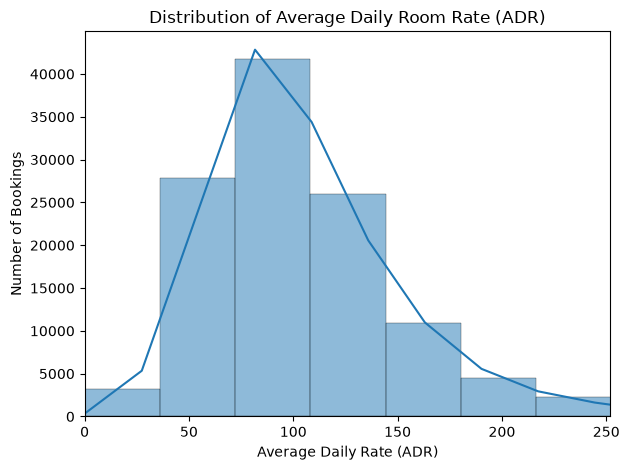

In [22]:
# 1. Distribution of ADR:

plt.figure()

sns.histplot(data=df, x="adr", bins=150, kde=True)

plt.xlim(0, df["adr"].quantile(0.99))

plt.title("Distribution of Average Daily Room Rate (ADR)")
plt.xlabel("Average Daily Rate (ADR)")
plt.ylabel("Number of Bookings")
plt.tight_layout()
plt.show()


ADR values peak around 75–100 and are positively skewed, with booking frequencies declining at higher room rates; the plot displays values up to the 99th percentile.

hotel_type_eda
City Hotel      78092
Resort Hotel    39307
Name: count, dtype: int64


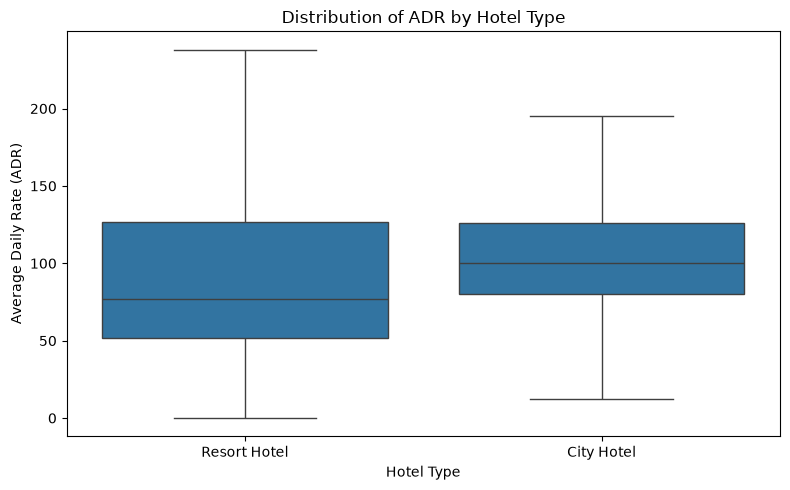

In [23]:
# 2. Compare ADR across hotel types:

df["hotel_type_eda"] = df["hotel_City Hotel"].map({1: "City Hotel", 0: "Resort Hotel"})

print(df["hotel_type_eda"].value_counts())

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="hotel_type_eda", y="adr", showfliers=False)

plt.title("Distribution of ADR by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Average Daily Rate (ADR)")
plt.tight_layout()
plt.show()

City Hotels exhibit a higher median ADR (approximately 100) than Resort Hotels (approximately 75), while Resort Hotels show a wider overall spread in the room rates.

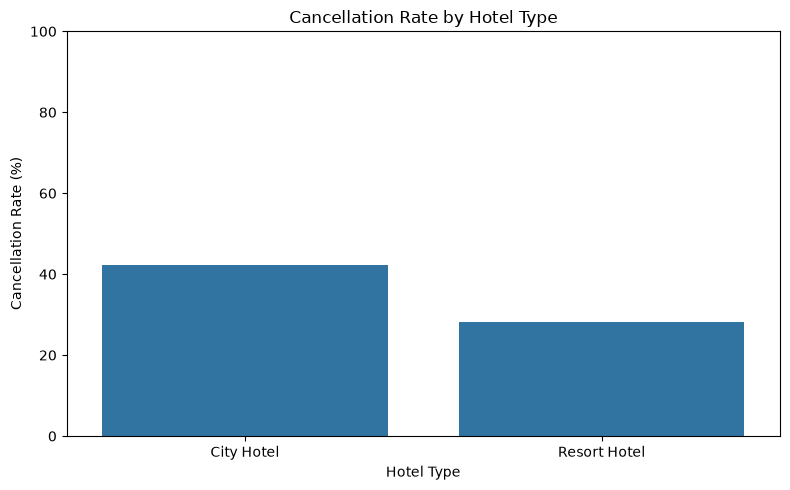

  hotel_type_eda  cancellation_rate
0     City Hotel          42.223275
1   Resort Hotel          28.081512


In [24]:
# 3. Cancellation rate by hotel type:

cancellation_by_hotel = (df.groupby("hotel_type_eda")["is_canceled"].mean().mul(100).reset_index(name="cancellation_rate"))

plt.figure(figsize=(8, 5))

sns.barplot(data=cancellation_by_hotel, x="hotel_type_eda", y="cancellation_rate")

plt.title("Cancellation Rate by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

print(cancellation_by_hotel)

City Hotels have a higher cancellation rate (approximately 42%) than Resort Hotels (approximately 28%), indicating that cancellations are more prevalent among City Hotel bookings in the cleaned dataset.

## Statistical Inferences:

### Test 1 (P1): Do cancelled bookings have a higher mean lead time?

**Variables**

- `lead_time`: Number of days between booking and arrival.
- `is_canceled`: 1 if the booking was cancelled, 0 otherwise.

**Statistical test:** One-sided Welch two-sample t-test.

**Why this test?** We compare the mean of a numerical variable (`lead_time`) across two independent groups: cancelled and non-cancelled bookings. Welch's t-test does not require the two groups to have equal population variances.

**Hypotheses**

Let $\mu_C$ be the population mean lead time for cancelled bookings and $\mu_N$ be the population mean lead time for non-cancelled bookings.

- $H_0: \mu_C \leq \mu_N$
- $H_1: \mu_C > \mu_N$

**Significance level:** $\alpha = 0.05$.

**Decision rule:** If the one-sided p-value is below 0.05, reject $H_0$. Otherwise, fail to reject $H_0$.

In [25]:
cancelled = df.loc[df["is_canceled"] == 1, "lead_time"]
not_cancelled = df.loc[df["is_canceled"] == 0, "lead_time"]

mean_cancelled = cancelled.mean()
mean_not_cancelled = not_cancelled.mean()
difference = mean_cancelled - mean_not_cancelled

result = ttest_ind(cancelled, not_cancelled, equal_var=False, alternative="greater")

ci_result = ttest_ind(cancelled, not_cancelled, equal_var=False, alternative="two-sided").confidence_interval(confidence_level=0.95)

print(f"Mean lead time (cancelled): {mean_cancelled:.2f} days")
print(f"Mean lead time (not cancelled): {mean_not_cancelled:.2f} days")
print(f"Mean difference: {difference:.2f} days")
print(f"95% confidence interval: ({ci_result.low:.2f}, {ci_result.high:.2f}) days")
print(f"t-statistic: {result.statistic:.4f}")
print(f"Degrees of freedom: {result.df:.2f}")
print(f"p-value: {result.pvalue:.6g}")
print("Decision:", "Reject H0" if result.pvalue < 0.05 else "Fail to reject H0")

Mean lead time (cancelled): 145.20 days
Mean lead time (not cancelled): 81.04 days
Mean difference: 64.16 days
95% confidence interval: (62.87, 65.45) days
t-statistic: 97.5505
Degrees of freedom: 75116.12
p-value: 0
Decision: Reject H0


### Test 2 (P2): Do previous cancellations relate to current cancellation status?

**Variables**

- `previous_cancellations`: Number of previous cancellations.
- `is_canceled`: 1 if the current booking was cancelled, 0 otherwise.

**Statistical test:** Two-sided two-proportion z-test.

**Why this test?** We compare the proportions of currently cancelled bookings between two independent groups: bookings with at least one previous cancellation and bookings with none.

**Hypotheses**

Let $p_1$ be the current cancellation rate among bookings with at least one previous cancellation, and $p_0$ be the rate among bookings with none.

- $H_0: p_1 = p_0$
- $H_1: p_1 \neq p_0$

**Significance level:** $\alpha = 0.05$.

**Decision rule:** If the p-value is below 0.05, reject $H_0$. Otherwise, fail to reject $H_0$.

In [26]:
group1 = df[df["previous_cancellations"] >= 1]["is_canceled"]

group0 = df[df["previous_cancellations"] == 0]["is_canceled"]

n1 = len(group1)
n0 = len(group0)
x1 = group1.sum()
x0 = group0.sum()

p1 = x1 / n1
p0 = x0 / n0
difference = p1 - p0

counts = np.array([x1, x0])
nobs = np.array([n1, n0])

z_stat, p_value = proportions_ztest(counts, nobs, alternative="two-sided")

se = np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
ci_low = difference - 1.96 * se
ci_high = difference + 1.96 * se


print(f"Cancellation rate (previous cancellations): {p1:.2%}")
print(f"Cancellation rate (no previous cancellations): {p0:.2%}")
print(f"Difference in cancellation rates: {difference:.2%}")
print(f"95% confidence interval: ({ci_low:.2%}, {ci_high:.2%})")
print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.6g}")
print("Decision:", "Reject H0" if p_value < 0.05 else "Fail to reject H0")

Cancellation rate (previous cancellations): 92.43%
Cancellation rate (no previous cancellations): 34.33%
Difference in cancellation rates: 58.10%
95% confidence interval: (57.40%, 58.81%)
Z-statistic: 93.3012
P-value: 0
Decision: Reject H0


### Test 3 (P3): Do City Hotel bookings that include weekends have a higher mean ADR?

**Variables**

- `adr`: Average Daily Rate of the booking.
- `includes_weekends`: 1 if the booking includes weekend nights, 0 otherwise.
- `hotel_type_eda`: Used to select City Hotel bookings.

**Statistical test:** One-sided Welch two-sample t-test.

**Why this test?** We compare the mean ADR between two independent groups of City Hotel bookings. Welch's t-test does not require the two groups to have equal population variances.

**Hypotheses**

Let $\mu_W$ be the population mean ADR for City Hotel bookings that include weekend nights, and $\mu_D$ be the mean ADR for weekday-only bookings.

- $H_0: \mu_W \leq \mu_D$
- $H_1: \mu_W > \mu_D$

**Significance level:** $\alpha = 0.05$.

**Decision rule:** If the p-value is below 0.05, reject $H_0$. Otherwise, fail to reject $H_0$.

In [27]:
city_df = df[df["hotel_type_eda"] == "City Hotel"]

weekend = city_df[city_df["includes_weekends"] == 1]["adr"]

weekday_only = city_df[city_df["includes_weekends"] == 0]["adr"]

mean_weekend = weekend.mean()
mean_weekday = weekday_only.mean()
difference = mean_weekend - mean_weekday


result = ttest_ind(weekend, weekday_only, equal_var=False, alternative="greater")

ci_result = ttest_ind(weekend, weekday_only, equal_var=False, alternative="two-sided").confidence_interval(confidence_level=0.95)

print(f"Mean ADR (weekend-inclusive): {mean_weekend:.2f}")
print(f"Mean ADR (weekday-only): {mean_weekday:.2f}")
print(f"Mean difference: {difference:.2f} ADR units")
print(f"95% confidence interval: ({ci_result.low:.2f}, {ci_result.high:.2f})")
print(f"t-statistic: {result.statistic:.4f}")
print(f"Degrees of freedom: {result.df:.2f}")
print(f"P-value: {result.pvalue:.6g}")
print("Decision:", "Reject H0" if result.pvalue < 0.05 else "Fail to reject H0")

Mean ADR (weekend-inclusive): 107.81
Mean ADR (weekday-only): 105.99
Mean difference: 1.81 ADR units
95% confidence interval: (1.22, 2.41)
t-statistic: 5.9650
Degrees of freedom: 70450.67
P-value: 1.22905e-09
Decision: Reject H0
